In [1]:
# test
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.feature_extraction import DictVectorizer

# 加载CSV文件（假设格式：行是突变，列是细胞，值为1/0/-1）
df = pd.read_csv("/Users/liqun/scMutraceProject/Data/cellLine/gCSM/gCellSNPMatrix.step3.1_excludeControlSites.csv", index_col=0)  # 第一列为突变名称
print(f"原始数据形状: {df.shape} (突变×细胞)")

# 将数据转换为二进制矩阵（1表示突变，0表示无突变）
# 这里假设数据中只有'Mut'表示突变，其他值表示无突变
# 注意：根据实际数据格式可能需要调整
# 将'Mut'和其他值转换为二进制
# 例如：'Mut' -> 1, 其他值 -> 0
df_transformed = df.applymap(lambda x: 1 if x == 'Mut' else 0)

# 转换为稀疏矩阵
sparse_mtx = sparse.csr_matrix(df_transformed.values, dtype=np.int8)

print(f"原始数据形状: {df.shape}")
print(f"突变事件总数: {sparse_mtx.sum()}") 
print(f"突变细胞比例: {np.mean(sparse_mtx.sum(axis=0) > 0):.2%}")

原始数据形状: (1810, 3154) (突变×细胞)


/var/folders/yx/vkjdxytj10n2fwzdpmn014bc0000gp/T/ipykernel_7933/1116418254.py:16: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_transformed = df.applymap(lambda x: 1 if x == 'Mut' else 0)


原始数据形状: (1810, 3154)
突变事件总数: 42929
突变细胞比例: 99.71%


In [ ]:
# 计算每个细胞的突变数量
mut_per_cell = np.array(sparse_mtx.sum(axis=0)).flatten()
print(f"\n每个细胞的突变数量: {mut_per_cell}")

# 设置阈值 (示例：至少1个突变)
min_mutations = 1
cell_mask = mut_per_cell >= min_mutations
filtered_mtx = sparse_mtx[:, cell_mask]

print(f"\n筛选后数据形状: {filtered_mtx.shape}")


每个细胞的突变数量: [32 15 16 ... 26  3 17]
(3154,)

筛选后数据形状: (1810, 3145)


In [7]:
# 计算每个突变出现的细胞数
mut_freq = np.array(filtered_mtx.sum(axis=1)).flatten()

# 设置阈值 (示例：至少在5个细胞中出现)
min_cells = 5
mut_mask = mut_freq >= min_cells
final_mtx = filtered_mtx[mut_mask, :]

print(f"\n最终数据形状: {final_mtx.shape}")


最终数据形状: (1738, 3145)


In [23]:
from sklearn.metrics.pairwise import pairwise_distances
from scipy.cluster.hierarchy import linkage, fcluster

# 计算Jaccard距离矩阵
jaccard_dist = pairwise_distances(final_mtx.T.toarray(), metric='jaccard')

# 层次聚类
Z = linkage(jaccard_dist, method='average')
clusters = fcluster(Z, t=2.42, criterion='distance')  # 调整t值控制聚类数

# 评估
from sklearn.metrics import silhouette_score
# Check the number of unique clusters
unique_clusters = np.unique(clusters)
if len(unique_clusters) > 1:
	score = silhouette_score(jaccard_dist, clusters, metric='precomputed')
	print(f"Silhouette Score: {score:.3f}")
else:
	print("Silhouette Score cannot be computed because there is only one cluster.")

/Users/liqun/anaconda3/envs/singleCell/lib/python3.10/site-packages/sklearn/metrics/pairwise.py:2008: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/var/folders/yx/vkjdxytj10n2fwzdpmn014bc0000gp/T/ipykernel_16140/2947540971.py:8: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  Z = linkage(jaccard_dist, method='average')


Silhouette Score: -0.047


t=10.00, clusters=1
t=9.58, clusters=1
t=9.16, clusters=1
t=8.74, clusters=1
t=8.32, clusters=1
t=7.89, clusters=1
t=7.47, clusters=1
t=7.05, clusters=1
t=6.63, clusters=1
t=6.21, clusters=1
t=5.79, clusters=1
t=5.37, clusters=1
t=4.95, clusters=1
t=4.53, clusters=1
t=4.11, clusters=1
t=3.68, clusters=1
t=3.26, clusters=1
t=2.84, clusters=1
t=2.42, clusters=9
t=2.00, clusters=361


Text(0, 0.5, 'Silhouette Score')

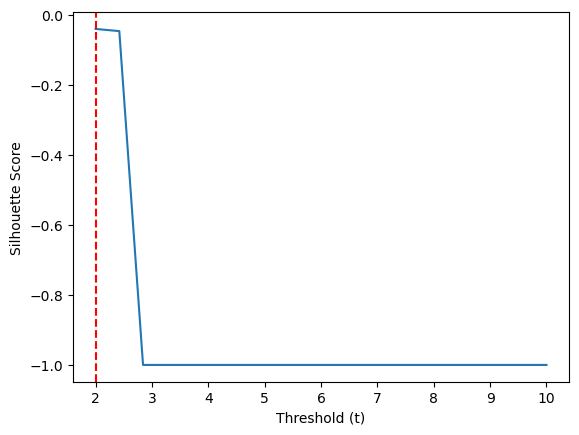

In [22]:
import matplotlib.pyplot as plt
t_values = np.linspace(10, 2, 20)  # 生成候选t值范围
scores = []

for t in t_values:
    clusters = fcluster(Z, t, criterion='distance')
    print(f"t={t:.2f}, clusters={len(np.unique(clusters))}")
    if len(np.unique(clusters)) > 1:  # 至少需要2个簇
        scores.append(silhouette_score(jaccard_dist, clusters, metric='precomputed'))
    else:
        scores.append(-1)  # 无效值

best_t = t_values[np.argmax(scores)]
plt.plot(t_values, scores)
plt.axvline(x=best_t, color='r', linestyle='--')
plt.xlabel('Threshold (t)')
plt.ylabel('Silhouette Score')

/Users/liqun/anaconda3/envs/singleCell/lib/python3.10/site-packages/umap/umap_.py:1887: UserWarning: gradient function is not yet implemented for jaccard distance metric; inverse_transform will be unavailable
  warn(
/Users/liqun/anaconda3/envs/singleCell/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


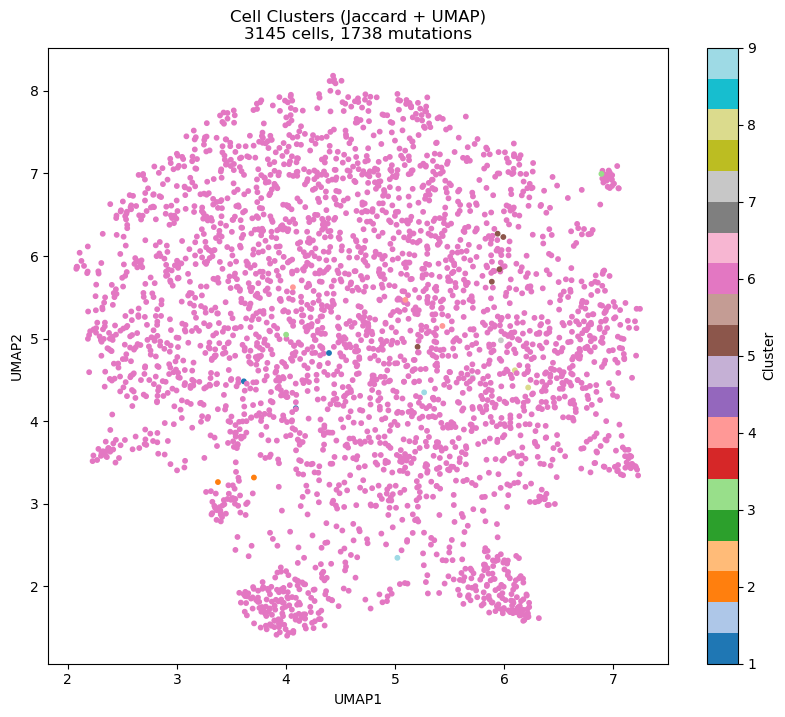

In [24]:
import umap
import matplotlib.pyplot as plt

# UMAP降维
reducer = umap.UMAP(metric='jaccard', random_state=42)
embedding = reducer.fit_transform(final_mtx.T)

# 绘制结果
plt.figure(figsize=(10, 8))
scatter = plt.scatter(embedding[:, 0], embedding[:, 1], 
                     c=clusters, cmap='tab20', s=10)
plt.colorbar(scatter, label='Cluster')
plt.title(f"Cell Clusters (Jaccard + UMAP)\n{final_mtx.shape[1]} cells, {final_mtx.shape[0]} mutations")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.show()